In [1]:
import os
import random
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from scipy.io import loadmat
import numpy as np
import pandas as pd
import torch.nn as nn


# -----------------------------
# Dataset & DataLoaders
# -----------------------------
class MixtureOfGaussiansDataset(Dataset):
    def __init__(self, csv_file, mat_dir, mat_prefix='ps_train', mat_suffix='.mat', max_n=None, transform=None):
        """
        Args:
            csv_file (str): 输入参数CSV文件的路径。
            mat_dir (str): 包含density矩阵的.mat文件的目录。
            mat_prefix (str): .mat文件名的前缀（如 'ps_train', 'ps_valid', 'ps_test'）。
            mat_suffix (str): .mat文件名的后缀，通常为 '.mat'。
            max_n (int, required): 需要填充的密度矩阵的最大尺寸。
            transform (callable, optional): 应用于样本的可选转换。
        """
        self.data_frame = pd.read_csv(csv_file)
        self.mat_dir = mat_dir
        self.mat_prefix = mat_prefix
        self.mat_suffix = mat_suffix
        self.transform = transform

        expected_mat_files = len(self.data_frame)
        actual_mat_files = len([f for f in os.listdir(mat_dir) if f.startswith(mat_prefix) and f.endswith(mat_suffix)])
        if actual_mat_files != expected_mat_files:
            raise ValueError(f"CSV文件中的样本数量 ({expected_mat_files}) 与.mat文件的数量 ({actual_mat_files}) 不匹配。")

        if max_n is None:
            raise ValueError("max_n必须指定，才能确保在所有数据集上找到最大尺寸。")
        self.max_n = max_n

        self.x_data, self.y_data = [], []
        for idx in range(expected_mat_files):
            params = self.data_frame.iloc[idx, :].values.astype(np.float32)
            x_tensor = torch.tensor(params, dtype=torch.float32)
            self.x_data.append(x_tensor)

            mat_filename = self.get_mat_filename(idx)
            mat_path = os.path.join(self.mat_dir, mat_filename)
            mat = loadmat(mat_path)
            density = mat.get('density')
            if density is None:
                raise KeyError(f"'density' 变量未在 {mat_path} 中找到。")
            density = density.astype(np.float32)
            density_tensor = torch.tensor(density)

            current_n = density_tensor.shape[0]
            pad_size = self.max_n - current_n
            if pad_size > 0:
                density_padded = F.pad(density_tensor, (0, pad_size, 0, pad_size), mode='constant', value=0)
            else:
                density_padded = density_tensor
            self.y_data.append(density_padded)

    def get_mat_filename(self, idx):
        file_number = idx + 1
        return f'{self.mat_prefix}{{{file_number}}}{self.mat_suffix}'

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        x = self.x_data[idx]
        y = self.y_data[idx]
        if self.transform:
            x = self.transform(x)
            y = self.transform(y)
        return x, y


def find_max_n(mat_dirs):
    max_n = 0
    for mat_dir, mat_prefix, mat_suffix in mat_dirs:
        for filename in os.listdir(mat_dir):
            if filename.startswith(mat_prefix) and filename.endswith(mat_suffix):
                mat_path = os.path.join(mat_dir, filename)
                mat = loadmat(mat_path)
                density = mat.get('density')
                if density is None:
                    raise KeyError(f"'density' variable not found in {mat_path}")
                current_n = density.shape[0]
                if current_n > max_n:
                    max_n = current_n
    return max_n


def prepare_dataloaders(csv_train, mat_train_dir, csv_valid, mat_valid_dir, csv_test, mat_test_dir,
                        batch_size=64, num_workers=4):
    mat_dirs = [
        (mat_train_dir, 'ps_train', '.mat'),
        (mat_valid_dir, 'ps_valid', '.mat'),
        (mat_test_dir,  'ps_test',  '.mat')
    ]

    max_n = find_max_n(mat_dirs)
    print(f"全数据集中最大密度矩阵尺寸: {max_n}x{max_n}")

    train_dataset = MixtureOfGaussiansDataset(
        csv_file=csv_train,
        mat_dir=mat_train_dir,
        mat_prefix='ps_train',
        mat_suffix='.mat',
        max_n=max_n
    )
    valid_dataset = MixtureOfGaussiansDataset(
        csv_file=csv_valid,
        mat_dir=mat_valid_dir,
        mat_prefix='ps_valid',
        mat_suffix='.mat',
        max_n=max_n
    )
    test_dataset = MixtureOfGaussiansDataset(
        csv_file=csv_test,
        mat_dir=mat_test_dir,
        mat_prefix='ps_test',
        mat_suffix='.mat',
        max_n=max_n
    )

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=True
    )
    valid_loader = DataLoader(
        valid_dataset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=True
    )
    test_loader = DataLoader(
        test_dataset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=True
    )

    return train_loader, valid_loader, test_loader, max_n


# -----------------------------
# Loss: Hellinger distance (discrete) + moment penalty
# -----------------------------
class HellingerDistanceLoss(nn.Module):
    def __init__(self, grid_x, grid_y, grid_area, device='cpu'):
        super(HellingerDistanceLoss, self).__init__()
        self.grid_x = grid_x.to(device)
        self.grid_y = grid_y.to(device)
        self.grid_area = grid_area

    def forward(self, weights, means, covariances, true_density):
        batch_size, num_components = weights.shape
        n = true_density.shape[1]
        eps = 1e-8

        mu_x = means[:, :, 0].unsqueeze(-1).unsqueeze(-1)
        mu_y = means[:, :, 1].unsqueeze(-1).unsqueeze(-1)

        sigma_xx = covariances[:, :, 0, 0].unsqueeze(-1).unsqueeze(-1)
        sigma_xy = covariances[:, :, 0, 1].unsqueeze(-1).unsqueeze(-1)
        sigma_yy = covariances[:, :, 1, 1].unsqueeze(-1).unsqueeze(-1)

        det_sigma = sigma_xx * sigma_yy - sigma_xy ** 2
        det_sigma = torch.clamp(det_sigma, min=1e-12)

        inv_sigma_xx = sigma_yy / det_sigma
        inv_sigma_xy = -sigma_xy / det_sigma
        inv_sigma_yy = sigma_xx / det_sigma

        gx = self.grid_x.unsqueeze(0).unsqueeze(0)
        gy = self.grid_y.unsqueeze(0).unsqueeze(0)
        dx = gx - mu_x
        dy = gy - mu_y

        exponent = -0.5 * (
            inv_sigma_xx * dx ** 2
            + 2 * inv_sigma_xy * dx * dy
            + inv_sigma_yy * dy ** 2
        )
        gaussian = (1.0 / (2 * torch.pi * torch.sqrt(det_sigma))) * torch.exp(exponent)

        w = weights.unsqueeze(-1).unsqueeze(-1)
        pred = torch.sum(w * gaussian, dim=1)
        pred = pred + eps
        pred = pred / pred.sum(dim=[1, 2], keepdim=True)

        true = true_density + eps
        true = true / true.sum(dim=[1, 2], keepdim=True)

        mean_pred_x = torch.sum(pred * self.grid_x, dim=[1, 2])
        mean_true_x = torch.sum(true * self.grid_x, dim=[1, 2])
        mean_pred_y = torch.sum(pred * self.grid_y, dim=[1, 2])
        mean_true_y = torch.sum(true * self.grid_y, dim=[1, 2])

        lamda = 0.02
        ratio_x = (mean_pred_x + 1e-6) / (mean_true_x + 1e-6)
        ratio_y = (mean_pred_y + 1e-6) / (mean_true_y + 1e-6)
        penalty = lamda * (torch.log10(ratio_x) ** 2 + torch.log10(ratio_y) ** 2)

        sqrt_pred = torch.sqrt(pred.view(batch_size, -1))
        sqrt_true = torch.sqrt(true.view(batch_size, -1))
        hell2 = 0.5 * torch.sum((sqrt_pred - sqrt_true) ** 2, dim=1)
        hell = torch.sqrt(torch.clamp(hell2, min=0.0) + 1e-12)

        total = hell.mean() + penalty.mean()
        return total, hell


# -----------------------------
# Model
# -----------------------------
class MixtureOfGaussiansModel(nn.Module):
    def __init__(self, input_dim=5, num_components=4, hidden_dims=None):
        super(MixtureOfGaussiansModel, self).__init__()
        if hidden_dims is None or len(hidden_dims) == 0:
            raise ValueError("hidden_dims 不能为空，且需至少包含一层。")
        if input_dim <= 0:
            raise ValueError("input_dim 必须为正整数。")
        if num_components <= 0:
            raise ValueError("num_components 必须为正整数。")

        self.input_dim = input_dim
        self.num_components = num_components
        self.hidden_dims = hidden_dims

        self.hidden_layers = nn.ModuleList()
        self.hidden_layers.append(nn.Linear(input_dim, hidden_dims[0]))
        for i in range(1, len(hidden_dims)):
            self.hidden_layers.append(nn.Linear(hidden_dims[i - 1], hidden_dims[i]))

        self.output_layer = nn.Linear(hidden_dims[-1], num_components * 6)

    def forward(self, x):
        batch_size = x.shape[0]
        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        output = self.output_layer(x).view(batch_size, self.num_components, 6)

        weights = F.softmax(output[:, :, 0], dim=1)
        means = output[:, :, 1:3]

        eps = 1e-6
        s_xx = F.softplus(output[:, :, 3]) + eps
        alpha = output[:, :, 4]
        rho = 2 * torch.sigmoid(alpha) - 1
        rho = torch.clamp(rho, -1 + 1e-4, 1 - 1e-4)
        s_yy = F.softplus(output[:, :, 5]) + eps
        sigma_xy = rho * torch.sqrt(s_xx * s_yy)

        covariances = torch.zeros(
            batch_size, self.num_components, 2, 2,
            device=output.device, dtype=output.dtype
        )
        covariances[:, :, 0, 0] = s_xx
        covariances[:, :, 0, 1] = sigma_xy
        covariances[:, :, 1, 0] = sigma_xy
        covariances[:, :, 1, 1] = s_yy

        return weights, means, covariances


# -----------------------------
# Utils
# -----------------------------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # 如你更追求完全可复现，可打开下面两行，但训练可能稍慢
    # torch.backends.cudnn.deterministic = True
    # torch.backends.cudnn.benchmark = False


def evaluate_model(model, data_loader, loss_fn, device):
    model.eval()
    losses = []
    hellinger_distances = []

    with torch.no_grad():
        for batch_x, batch_y in data_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            weights, means, covariances = model(batch_x)
            total_loss, hellinger_distance = loss_fn(weights, means, covariances, batch_y)

            losses.append(total_loss.item())
            hellinger_distances.append(hellinger_distance.mean().item())

    avg_loss = float(np.mean(losses))
    avg_hell = float(np.mean(hellinger_distances))
    return avg_loss, avg_hell


# -----------------------------
# Train / Eval
# -----------------------------
def train_model(
    csv_train, mat_train_dir, csv_valid, mat_valid_dir, csv_test, mat_test_dir,
    num_epochs, batch_size, learning_rate, min_learning_rate, num_workers,
    hidden_dims, input_dim, num_components, run_idx, save_dir, seed
):
    print("=" * 90)
    print(f"[Run {run_idx:02d}] 开始训练")
    print(f"[Run {run_idx:02d}] seed = {seed}")
    print(f"[Run {run_idx:02d}] hidden_dims = {hidden_dims}")
    print(f"[Run {run_idx:02d}] input_dim = {input_dim}, num_components = {num_components}")

    set_seed(seed)
    os.makedirs(save_dir, exist_ok=True)

    train_loader, valid_loader, test_loader, max_n = prepare_dataloaders(
        csv_train=csv_train,
        mat_train_dir=mat_train_dir,
        csv_valid=csv_valid,
        mat_valid_dir=mat_valid_dir,
        csv_test=csv_test,
        mat_test_dir=mat_test_dir,
        batch_size=batch_size,
        num_workers=num_workers
    )

    lim = max_n * 0.1
    edges = torch.linspace(0.05, lim - 0.05, steps=max_n)
    grid_x, grid_y = torch.meshgrid(edges, edges, indexing='ij')
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    grid_x = grid_x.to(device)
    grid_y = grid_y.to(device)
    grid_area = 0.1 * 0.1

    model = MixtureOfGaussiansModel(
        input_dim=input_dim,
        num_components=num_components,
        hidden_dims=hidden_dims
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.1, patience=10, min_lr=min_learning_rate
    )
    loss_fn = HellingerDistanceLoss(grid_x, grid_y, grid_area, device=device).to(device)

    dims_tag = "-".join(map(str, hidden_dims))

    # 先用临时文件名保存该 run 的验证集最优模型
    temp_ckpt_path = os.path.join(
        save_dir,
        f"best_model_in{input_dim}_K{num_components}_{dims_tag}_run{run_idx:02d}_bestval_tmp.pth"
    )

    best_val_loss = float('inf')
    best_val_hellinger = None
    patience = 50
    trigger_times = 0
    best_epoch = 0

    for epoch in range(num_epochs):
        model.train()
        train_losses = []
        train_hellinger_distances = []

        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            weights, means, covariances = model(batch_x)
            total_loss, hellinger_distance = loss_fn(weights, means, covariances, batch_y)
            total_loss.backward()
            optimizer.step()

            train_losses.append(total_loss.item())
            train_hellinger_distances.append(hellinger_distance.mean().item())

        avg_train_loss = float(np.mean(train_losses))
        avg_train_hellinger = float(np.mean(train_hellinger_distances))

        avg_val_loss, avg_val_hellinger = evaluate_model(model, valid_loader, loss_fn, device)

        scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]['lr']

        print(
            f"[Run {run_idx:02d}] Epoch [{epoch + 1}/{num_epochs}], "
            f"Train Loss: {avg_train_loss:.6f}, Train Hellinger: {avg_train_hellinger:.6f}, "
            f"Val Loss: {avg_val_loss:.6f}, Val Hellinger: {avg_val_hellinger:.6f}, "
            f"Current LR: {current_lr:.6f}"
        )

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_val_hellinger = avg_val_hellinger
            best_epoch = epoch + 1
            torch.save(model.state_dict(), temp_ckpt_path)
            print(f"[Run {run_idx:02d}] 保存最佳模型到 {temp_ckpt_path}")
            trigger_times = 0
        else:
            trigger_times += 1
            print(f"[Run {run_idx:02d}] 验证损失未改善轮数: {trigger_times}")
            if trigger_times >= patience:
                print(f"[Run {run_idx:02d}] 达到早停条件，停止训练。")
                break

    # 加载该 run 验证集最优模型，再做测试
    model.load_state_dict(torch.load(temp_ckpt_path, map_location=device))
    model.to(device)

    avg_test_loss, avg_test_hellinger = evaluate_model(model, test_loader, loss_fn, device)

    # 最终模型名：在原基础上添加 run 编号 + 测试集 loss
    final_ckpt_name = (
        f"best_model_in{input_dim}_K{num_components}_{dims_tag}"
        f"_run{run_idx:02d}_testloss{avg_test_loss:.6f}.pth"
    )
    final_ckpt_path = os.path.join(save_dir, final_ckpt_name)

    os.replace(temp_ckpt_path, final_ckpt_path)

    print(
        f"[Run {run_idx:02d}] 测试集平均 Total Loss: {avg_test_loss:.6f}, "
        f"平均 Hellinger Distance: {avg_test_hellinger:.6f}"
    )
    print(f"[Run {run_idx:02d}] 最终模型已保存到: {final_ckpt_path}")

    result = {
        "run": run_idx,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_hellinger": best_val_hellinger,
        "test_loss": avg_test_loss,
        "test_hellinger": avg_test_hellinger,
        "model_path": final_ckpt_path
    }
    return result



In [7]:
if __name__ == "__main__":
    # 数据路径
    csv_train = 'ps_train_filtered.csv'
    mat_train_dir = 'density_results_ps_train_edges=0.1（未转置）_filtered'
    csv_valid = 'ps_valid_filtered.csv'
    mat_valid_dir = 'density_results_ps_valid_edges=0.1（未转置）_filtered'
    csv_test = 'ps_test_filtered.csv'
    mat_test_dir = 'density_results_ps_test_edges=0.1（未转置）_filtered'

    # 训练参数
    num_epochs = 3000
    batch_size = 32
    learning_rate = 1e-3
    num_workers = 0
    min_learning_rate = learning_rate / 32

    input_dim = 4
    num_components = 3
    hidden_dims = [512, 1024, 512]

    # 新增参数
    num_runs = 30
    base_seed = 2026
    save_dir = "saved_models_10runs_DRL"

    all_results = []

    for run_idx in range(1, num_runs + 1):
        seed = base_seed + run_idx

        result = train_model(
            csv_train=csv_train,
            mat_train_dir=mat_train_dir,
            csv_valid=csv_valid,
            mat_valid_dir=mat_valid_dir,
            csv_test=csv_test,
            mat_test_dir=mat_test_dir,
            num_epochs=num_epochs,
            batch_size=batch_size,
            learning_rate=learning_rate,
            num_workers=num_workers,
            min_learning_rate=min_learning_rate,
            hidden_dims=hidden_dims,
            input_dim=input_dim,
            num_components=num_components,
            run_idx=run_idx,
            save_dir=save_dir,
            seed=seed
        )

        all_results.append(result)

    df = pd.DataFrame(all_results)
    summary_csv_path = os.path.join(save_dir, "training_10runs_summaryK3.csv")
    df.to_csv(summary_csv_path, index=False, encoding="utf-8-sig")

    print("\n" + "=" * 90)
    print("10 次训练全部完成。结果汇总如下：")
    print(df)
    print(f"\n汇总 CSV 已保存到: {summary_csv_path}")

[Run 01] 开始训练
[Run 01] seed = 2027
[Run 01] hidden_dims = [512, 1024, 512]
[Run 01] input_dim = 4, num_components = 3
全数据集中最大密度矩阵尺寸: 324x324
[Run 01] Epoch [1/3000], Train Loss: 0.962503, Train Hellinger: 0.954044, Val Loss: 0.940675, Val Hellinger: 0.939721, Current LR: 0.001000
[Run 01] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run01_bestval_tmp.pth
[Run 01] Epoch [2/3000], Train Loss: 0.925825, Train Hellinger: 0.925144, Val Loss: 0.925320, Val Hellinger: 0.924723, Current LR: 0.001000
[Run 01] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run01_bestval_tmp.pth
[Run 01] Epoch [3/3000], Train Loss: 0.923332, Train Hellinger: 0.922776, Val Loss: 0.924429, Val Hellinger: 0.923820, Current LR: 0.001000
[Run 01] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run01_bestval_tmp.pth
[Run 01] Epoch [4/3000], Train Loss: 0.917017, Train Hellinger: 0.916592, Val Loss: 0.934407, Val Hellinger: 0.933754, Current LR: 0.001000
[Run 01] 验证损失未改善轮

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24256\3101688730.py:412: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(temp_ckpt_path, map_loca

全数据集中最大密度矩阵尺寸: 324x324
[Run 02] Epoch [1/3000], Train Loss: 0.980329, Train Hellinger: 0.971771, Val Loss: 0.952562, Val Hellinger: 0.950915, Current LR: 0.001000
[Run 02] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run02_bestval_tmp.pth
[Run 02] Epoch [2/3000], Train Loss: 0.937186, Train Hellinger: 0.935959, Val Loss: 0.912843, Val Hellinger: 0.911878, Current LR: 0.001000
[Run 02] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run02_bestval_tmp.pth
[Run 02] Epoch [3/3000], Train Loss: 0.917200, Train Hellinger: 0.915862, Val Loss: 0.914118, Val Hellinger: 0.913300, Current LR: 0.001000
[Run 02] 验证损失未改善轮数: 1
[Run 02] Epoch [4/3000], Train Loss: 0.908463, Train Hellinger: 0.907255, Val Loss: 0.854973, Val Hellinger: 0.854059, Current LR: 0.001000
[Run 02] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run02_bestval_tmp.pth
[Run 02] Epoch [5/3000], Train Loss: 0.898300, Train Hellinger: 0.897463, Val Loss: 0.843792, Val Hellinger: 0.84

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24256\3101688730.py:412: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(temp_ckpt_path, map_loca

全数据集中最大密度矩阵尺寸: 324x324
[Run 03] Epoch [1/3000], Train Loss: 0.958850, Train Hellinger: 0.950544, Val Loss: 0.936014, Val Hellinger: 0.935200, Current LR: 0.001000
[Run 03] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run03_bestval_tmp.pth
[Run 03] Epoch [2/3000], Train Loss: 0.925578, Train Hellinger: 0.924923, Val Loss: 0.926555, Val Hellinger: 0.925981, Current LR: 0.001000
[Run 03] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run03_bestval_tmp.pth
[Run 03] Epoch [3/3000], Train Loss: 0.920817, Train Hellinger: 0.920284, Val Loss: 0.920138, Val Hellinger: 0.919760, Current LR: 0.001000
[Run 03] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run03_bestval_tmp.pth
[Run 03] Epoch [4/3000], Train Loss: 0.913695, Train Hellinger: 0.913316, Val Loss: 0.910663, Val Hellinger: 0.910416, Current LR: 0.001000
[Run 03] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run03_bestval_tmp.pth
[Run 03] Epoch [5/3000], Train Loss: 0.91

...

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24256\3101688730.py:412: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(temp_ckpt_path, map_loca

全数据集中最大密度矩阵尺寸: 324x324
[Run 14] Epoch [1/3000], Train Loss: 0.962650, Train Hellinger: 0.952677, Val Loss: 0.936642, Val Hellinger: 0.935405, Current LR: 0.001000
[Run 14] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run14_bestval_tmp.pth
[Run 14] Epoch [2/3000], Train Loss: 0.914225, Train Hellinger: 0.913519, Val Loss: 0.903310, Val Hellinger: 0.902542, Current LR: 0.001000
[Run 14] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run14_bestval_tmp.pth
[Run 14] Epoch [3/3000], Train Loss: 0.892905, Train Hellinger: 0.892295, Val Loss: 0.874353, Val Hellinger: 0.873618, Current LR: 0.001000
[Run 14] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run14_bestval_tmp.pth
[Run 14] Epoch [4/3000], Train Loss: 0.886969, Train Hellinger: 0.886384, Val Loss: 0.897527, Val Hellinger: 0.896986, Current LR: 0.001000
[Run 14] 验证损失未改善轮数: 1
[Run 14] Epoch [5/3000], Train Loss: 0.878522, Train Hellinger: 0.877934, Val Loss: 0.855944, Val Hellinger: 0.85

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24256\3101688730.py:412: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(temp_ckpt_path, map_loca

全数据集中最大密度矩阵尺寸: 324x324
[Run 15] Epoch [1/3000], Train Loss: 0.964680, Train Hellinger: 0.955966, Val Loss: 0.934194, Val Hellinger: 0.933357, Current LR: 0.001000
[Run 15] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run15_bestval_tmp.pth
[Run 15] Epoch [2/3000], Train Loss: 0.942509, Train Hellinger: 0.941338, Val Loss: 0.991070, Val Hellinger: 0.989818, Current LR: 0.001000
[Run 15] 验证损失未改善轮数: 1
[Run 15] Epoch [3/3000], Train Loss: 0.921836, Train Hellinger: 0.920413, Val Loss: 0.971719, Val Hellinger: 0.971026, Current LR: 0.001000
[Run 15] 验证损失未改善轮数: 2
[Run 15] Epoch [4/3000], Train Loss: 0.924783, Train Hellinger: 0.923550, Val Loss: 0.873797, Val Hellinger: 0.872905, Current LR: 0.001000
[Run 15] 保存最佳模型到 saved_models_10runs_DRL\best_model_in4_K3_512-1024-512_run15_bestval_tmp.pth
[Run 15] Epoch [5/3000], Train Loss: 0.912632, Train Hellinger: 0.911714, Val Loss: 0.942177, Val Hellinger: 0.941368, Current LR: 0.001000
[Run 15] 验证损失未改善轮数: 1
[Run 15] Epoch [6/3000]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2356\3992564416.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


预测的混合权重：
[[8.6931109e-01 1.3068232e-01 6.5378140e-06]]
预测的均值，非负训练坐标系：
[[[11.656975 22.981813]
  [11.635003 10.840687]
  [12.05945  15.549511]]]
预测的协方差矩阵：
[[[[ 0.15110081 -0.03926378]
   [-0.03926378  0.24533266]]

  [[ 0.15287901  0.05636691]
   [ 0.05636691  0.07741576]]

  [[ 0.13653812 -0.00764999]
   [-0.00764999  0.36509305]]]]
预测的均值，平移回原始坐标系后：
[[ 2.0569744 13.381813 ]
 [ 2.0350027  1.2406864]
 [ 2.4594498  5.9495106]]
交换 X/Y 轴后的均值坐标：
[[13.381813   2.0569744]
 [ 1.2406864  2.0350027]
 [ 5.9495106  2.4594498]]


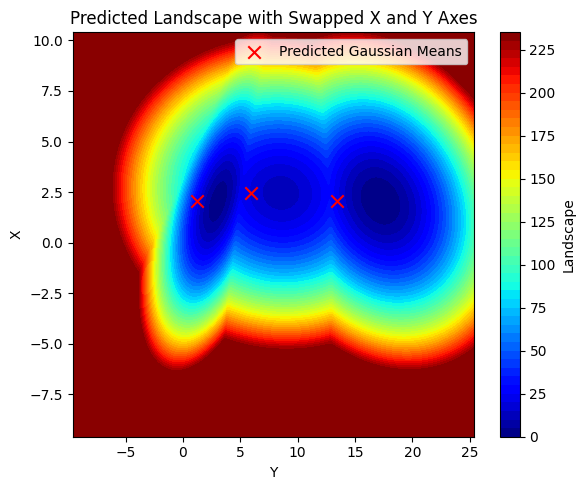

In [11]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=4,
    num_components=3,
    hidden_dims=[512, 1024, 512]
)

model.load_state_dict(
    torch.load(
        'saved_models_10runs_DRL/best_model_in4_K3_512-1024-512_run11_testloss0.097046.pth',
        map_location='cpu'
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
input_params = [3.8, 0.4, 1, 0.2828]   #main
#input_params = [3.8,	0.35,	1,	0.25]

x_input = torch.tensor([input_params], dtype=torch.float32)


# ============================================================
# 3. 得到模型预测输出
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

print("预测的混合权重：")
print(weights.numpy())

print("预测的均值，非负训练坐标系：")
print(means.numpy())

print("预测的协方差矩阵：")
print(covariances.numpy())


# ============================================================
# 4. 转为 numpy
# ============================================================
weights_np = weights[0].cpu().numpy()
means_np = means[0].cpu().numpy()
covariances_np = covariances[0].cpu().numpy()


# ============================================================
# 5. 设置训练时使用的非负坐标范围
# ============================================================
# 这里要和你训练代码中的网格一致
# 如果你的训练数据是 edges=0.05，则 dx = 0.05
dx = 0.1

# 这里设置模型坐标系中的绘图范围
# 例如训练时 max_n = 400，则非负坐标中心大概是 0.025 到 19.975
# 你也可以根据自己的 max_n 修改
x_model_min = 0.0
x_model_max = 20.0
y_model_min = 0.0
y_model_max = 30.0

num_x = 400
num_y = 400

x_model = np.linspace(x_model_min, x_model_max, num_x)
y_model = np.linspace(y_model_min, y_model_max, num_y)

X_model, Y_model = np.meshgrid(x_model, y_model)
pos_model = np.dstack((X_model, Y_model))


# ============================================================
# 6. 在非负模型坐标系中计算 GMM 密度
# ============================================================
Z = np.zeros(X_model.shape)

for i in range(len(weights_np)):
    rv = multivariate_normal(
        mean=means_np[i],
        cov=covariances_np[i],
        allow_singular=True
    )

    Z += weights_np[i] * rv.pdf(pos_model)


# ============================================================
# 7. 把坐标轴平移回真实 Xedges / Yedges 坐标
# ============================================================
# 重要：
# 这里填你的原始数据统一网格的 Xedges[0] 和 Yedges[0]
# 也就是原始边界最小值，而不是中心点最小值
#
# 举例：
# 如果原始 Xedges = [-10.0, -9.95, -9.90, ...]
# 那么 X_MIN = -10.0
#
# 如果原始 Yedges = [-8.0, -7.95, -7.90, ...]
# 那么 Y_MIN = -8.0

X_MIN = -9.6   # <<< 改成你的原始 Xedges 最小值
Y_MIN = -9.6   # <<< 改成你的原始 Yedges 最小值

X_true = X_model + X_MIN
Y_true = Y_model + Y_MIN

means_true = means_np.copy()
means_true[:, 0] = means_true[:, 0] + X_MIN
means_true[:, 1] = means_true[:, 1] + Y_MIN

print("预测的均值，平移回原始坐标系后：")
print(means_true)



# ============================================================
# 8. 计算 landscape
# ============================================================
landscape = -np.log(np.maximum(Z, 1e-100))


# ============================================================
# 9. 交换 X、Y 轴
#    原来：横轴 X，纵轴 Y，数据是 landscape.shape = (num_y, num_x)
#    现在：横轴 Y，纵轴 X，所以要把数据转置
# ============================================================
X_swap, Y_swap = np.meshgrid(y_true, x_true)   # 横轴变成 y_true，纵轴变成 x_true
landscape_swap = landscape.T                   # 转置以匹配新坐标

means_swap = means_true.copy()
means_swap[:, 0] = means_true[:, 1]   # 新横坐标 = 原 Y
means_swap[:, 1] = means_true[:, 0]   # 新纵坐标 = 原 X

print("交换 X/Y 轴后的均值坐标：")
print(means_swap)


# ============================================================
# 10. 绘制交换 X/Y 轴后的 landscape
# ============================================================
plt.figure(figsize=(6, 5))

plt.contourf(
    X_swap,
    Y_swap,
    landscape_swap,
    levels=50,
    cmap='jet'
)

plt.colorbar(label='Landscape')

plt.scatter(
    means_swap[:, 0],
    means_swap[:, 1],
    c='red',
    marker='x',
    s=80,
    label='Predicted Gaussian Means'
)

plt.title("Predicted Landscape with Swapped X and Y Axes")
plt.xlabel("Y")   # 横轴现在是原来的 Y
plt.ylabel("X")   # 纵轴现在是原来的 X
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2356\1849768537.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


原始预测的混合权重：
[[8.6931109e-01 1.3068232e-01 6.5378140e-06]]
原始预测的均值，非负训练坐标系：
[[[11.656975 22.981813]
  [11.635003 10.840687]
  [12.05945  15.549511]]]
原始预测的协方差矩阵：
[[[[ 0.15110081 -0.03926378]
   [-0.03926378  0.24533266]]

  [[ 0.15287901  0.05636691]
   [ 0.05636691  0.07741576]]

  [[ 0.13653812 -0.00764999]
   [-0.00764999  0.36509305]]]]
过滤小权重后的混合权重：
[0.8693168  0.13068318]
过滤小权重后的均值，非负训练坐标系：
[[11.656975 22.981813]
 [11.635003 10.840687]]
过滤小权重后的协方差矩阵：
[[[ 0.15110081 -0.03926378]
  [-0.03926378  0.24533266]]

 [[ 0.15287901  0.05636691]
  [ 0.05636691  0.07741576]]]
过滤后预测的均值，平移回原始坐标系后：
[[ 2.0569744 13.381813 ]
 [ 2.0350027  1.2406864]]
交换 X/Y 轴后的均值坐标：
[[13.381813   2.0569744]
 [ 1.2406864  2.0350027]]


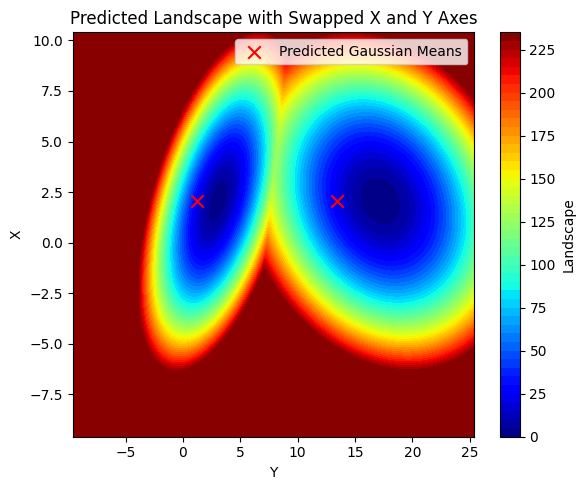

In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=4,
    num_components=3,
    hidden_dims=[512, 1024, 512]
)

model.load_state_dict(
    torch.load(
        'saved_models_10runs_DRL/best_model_in4_K3_512-1024-512_run11_testloss0.097046.pth',
        map_location='cpu'
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
input_params = [3.8, 0.4, 1, 0.2828]   # main
#input_params = [3.8, 0.35, 1, 0.25]

x_input = torch.tensor([input_params], dtype=torch.float32)


# ============================================================
# 3. 得到模型预测输出
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

print("原始预测的混合权重：")
print(weights.numpy())

print("原始预测的均值，非负训练坐标系：")
print(means.numpy())

print("原始预测的协方差矩阵：")
print(covariances.numpy())


# ============================================================
# 4. 转为 numpy，并过滤掉过小权重
# ============================================================
weights_np = weights[0].cpu().numpy()
means_np = means[0].cpu().numpy()
covariances_np = covariances[0].cpu().numpy()

weight_threshold = 1e-4
valid_idx = weights_np >= weight_threshold

# 如果全部都被过滤掉，则保留最大权重对应的成分，避免后续报错
if np.sum(valid_idx) == 0:
    max_idx = np.argmax(weights_np)
    valid_idx[max_idx] = True

weights_np = weights_np[valid_idx]
means_np = means_np[valid_idx]
covariances_np = covariances_np[valid_idx]

# 对剩余权重重新归一化
weights_np = weights_np / np.sum(weights_np)

print("过滤小权重后的混合权重：")
print(weights_np)

print("过滤小权重后的均值，非负训练坐标系：")
print(means_np)

print("过滤小权重后的协方差矩阵：")
print(covariances_np)


# ============================================================
# 5. 设置训练时使用的非负坐标范围
# ============================================================
dx = 0.1

# 这里设置模型坐标系中的绘图范围
x_model_min = 0.0
x_model_max = 20.0
y_model_min = 0.0
y_model_max = 30.0

num_x = 400
num_y = 400

x_model = np.linspace(x_model_min, x_model_max, num_x)
y_model = np.linspace(y_model_min, y_model_max, num_y)

X_model, Y_model = np.meshgrid(x_model, y_model)
pos_model = np.dstack((X_model, Y_model))


# ============================================================
# 6. 在非负模型坐标系中计算 GMM 密度
# ============================================================
Z = np.zeros(X_model.shape)

for i in range(len(weights_np)):
    rv = multivariate_normal(
        mean=means_np[i],
        cov=covariances_np[i],
        allow_singular=True
    )
    Z += weights_np[i] * rv.pdf(pos_model)


# ============================================================
# 7. 把坐标轴平移回真实 Xedges / Yedges 坐标
# ============================================================
# 这里填你的原始统一网格 Xedges[0], Yedges[0]
X_MIN = -9.6
Y_MIN = -9.6

X_true = X_model + X_MIN
Y_true = Y_model + Y_MIN

means_true = means_np.copy()
means_true[:, 0] = means_true[:, 0] + X_MIN
means_true[:, 1] = means_true[:, 1] + Y_MIN

print("过滤后预测的均值，平移回原始坐标系后：")
print(means_true)



# ============================================================
# 8. 计算 landscape
# ============================================================
landscape = -np.log(np.maximum(Z, 1e-100))


# ============================================================
# 9. 交换 X、Y 轴
#    原来：横轴 X，纵轴 Y，数据是 landscape.shape = (num_y, num_x)
#    现在：横轴 Y，纵轴 X，所以要把数据转置
# ============================================================
X_swap, Y_swap = np.meshgrid(y_true, x_true)   # 横轴变成 y_true，纵轴变成 x_true
landscape_swap = landscape.T                   # 转置以匹配新坐标

means_swap = means_true.copy()
means_swap[:, 0] = means_true[:, 1]   # 新横坐标 = 原 Y
means_swap[:, 1] = means_true[:, 0]   # 新纵坐标 = 原 X

print("交换 X/Y 轴后的均值坐标：")
print(means_swap)


# ============================================================
# 10. 绘制交换 X/Y 轴后的 landscape
# ============================================================
plt.figure(figsize=(6, 5))

plt.contourf(
    X_swap,
    Y_swap,
    landscape_swap,
    levels=50,
    cmap='jet'
)

plt.colorbar(label='Landscape')

plt.scatter(
    means_swap[:, 0],
    means_swap[:, 1],
    c='red',
    marker='x',
    s=80,
    label='Predicted Gaussian Means'
)

plt.title("Predicted Landscape with Swapped X and Y Axes")
plt.xlabel("Y")   # 横轴现在是原来的 Y
plt.ylabel("X")   # 纵轴现在是原来的 X
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2356\4277729359.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


原始预测的混合权重：
[[8.6931109e-01 1.3068232e-01 6.5378140e-06]]
原始预测的均值（非负训练坐标系）：
[[[11.656975 22.981813]
  [11.635003 10.840687]
  [12.05945  15.549511]]]
原始预测的协方差矩阵：
[[[[ 0.15110081 -0.03926378]
   [-0.03926378  0.24533266]]

  [[ 0.15287901  0.05636691]
   [ 0.05636691  0.07741576]]

  [[ 0.13653812 -0.00764999]
   [-0.00764999  0.36509305]]]]
过滤小权重后的混合权重：
[0.8693168  0.13068318]
过滤小权重后的均值（非负训练坐标系）：
[[11.656975 22.981813]
 [11.635003 10.840687]]
过滤小权重后的协方差矩阵：
[[[ 0.15110081 -0.03926378]
  [-0.03926378  0.24533266]]

 [[ 0.15287901  0.05636691]
  [ 0.05636691  0.07741576]]]
过滤后预测的均值（平移回原始坐标系后）：
[[ 2.0569744 13.381813 ]
 [ 2.0350027  1.2406864]]
交换 X/Y 轴后的均值坐标：
[[13.381813   2.0569744]
 [ 1.2406864  2.0350027]]


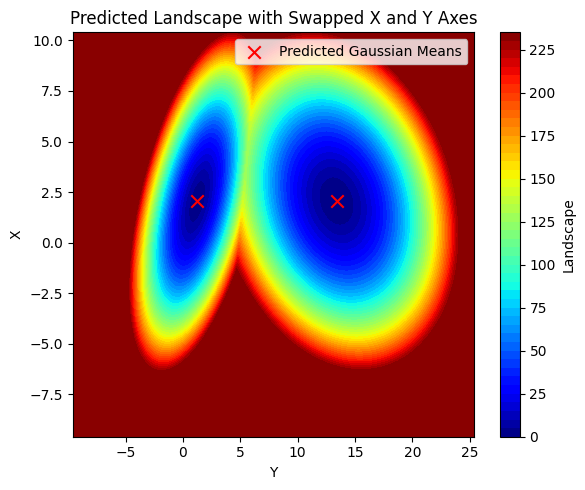

In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal


# ============================================================
# 1. 加载模型
# ============================================================
model = MixtureOfGaussiansModel(
    input_dim=4,
    num_components=3,
    hidden_dims=[512, 1024, 512]
)

model.load_state_dict(
    torch.load(
        'saved_models_10runs_DRL/best_model_in4_K3_512-1024-512_run11_testloss0.097046.pth',
        map_location='cpu'
    )
)

model.eval()


# ============================================================
# 2. 输入一组参数
# ============================================================
input_params = [3.8, 0.4, 1, 0.2828]   # main
#input_params = [3.8, 0.35, 1, 0.25]

x_input = torch.tensor([input_params], dtype=torch.float32)


# ============================================================
# 3. 得到模型预测输出
# ============================================================
with torch.no_grad():
    weights, means, covariances = model(x_input)

print("原始预测的混合权重：")
print(weights.numpy())

print("原始预测的均值（非负训练坐标系）：")
print(means.numpy())

print("原始预测的协方差矩阵：")
print(covariances.numpy())


# ============================================================
# 4. 转为 numpy，并过滤掉过小权重
# ============================================================
weights_np = weights[0].cpu().numpy()
means_np = means[0].cpu().numpy()
covariances_np = covariances[0].cpu().numpy()

weight_threshold = 1e-4
valid_idx = weights_np >= weight_threshold

# 如果全部都被过滤掉，则保留最大权重对应的成分，避免后续报错
if np.sum(valid_idx) == 0:
    max_idx = np.argmax(weights_np)
    valid_idx[max_idx] = True

weights_np = weights_np[valid_idx]
means_np = means_np[valid_idx]
covariances_np = covariances_np[valid_idx]

# 对剩余权重重新归一化
weights_np = weights_np / np.sum(weights_np)

print("过滤小权重后的混合权重：")
print(weights_np)

print("过滤小权重后的均值（非负训练坐标系）：")
print(means_np)

print("过滤小权重后的协方差矩阵：")
print(covariances_np)


# ============================================================
# 5. 设置训练时使用的非负坐标范围
# ============================================================
dx = 0.1

x_model_min = 0.0
x_model_max = 20.0
y_model_min = 0.0
y_model_max = 35.0

num_x = 400
num_y = 400

x_model = np.linspace(x_model_min, x_model_max, num_x)
y_model = np.linspace(y_model_min, y_model_max, num_y)

X_model, Y_model = np.meshgrid(x_model, y_model)
pos_model = np.dstack((X_model, Y_model))


# ============================================================
# 6. 在非负模型坐标系中计算 GMM 密度
# ============================================================
Z = np.zeros(X_model.shape)

for i in range(len(weights_np)):
    rv = multivariate_normal(
        mean=means_np[i],
        cov=covariances_np[i],
        allow_singular=True
    )
    Z += weights_np[i] * rv.pdf(pos_model)


# ============================================================
# 7. 把坐标轴平移回真实 Xedges / Yedges 坐标
# ============================================================
# 这里填你的原始统一网格 Xedges[0], Yedges[0]
X_MIN = -9.6
Y_MIN = -9.6

x_true = x_model + X_MIN
y_true = y_model + Y_MIN

means_true = means_np.copy()
means_true[:, 0] = means_true[:, 0] + X_MIN
means_true[:, 1] = means_true[:, 1] + Y_MIN

print("过滤后预测的均值（平移回原始坐标系后）：")
print(means_true)


# ============================================================
# 8. 计算 landscape
# ============================================================
landscape = -np.log(np.maximum(Z, 1e-100))


# ============================================================
# 9. 交换 X、Y 轴
#    原来：横轴 X，纵轴 Y，数据是 landscape.shape = (num_y, num_x)
#    现在：横轴 Y，纵轴 X，所以要把数据转置
# ============================================================
X_swap, Y_swap = np.meshgrid(y_true, x_true)   # 横轴变成 y_true，纵轴变成 x_true
landscape_swap = landscape.T                   # 转置以匹配新坐标

means_swap = means_true.copy()
means_swap[:, 0] = means_true[:, 1]   # 新横坐标 = 原 Y
means_swap[:, 1] = means_true[:, 0]   # 新纵坐标 = 原 X

print("交换 X/Y 轴后的均值坐标：")
print(means_swap)


# ============================================================
# 10. 绘制交换 X/Y 轴后的 landscape
# ============================================================
plt.figure(figsize=(6, 5))

plt.contourf(
    X_swap,
    Y_swap,
    landscape_swap,
    levels=50,
    cmap='jet'
)

plt.colorbar(label='Landscape')

plt.scatter(
    means_swap[:, 0],
    means_swap[:, 1],
    c='red',
    marker='x',
    s=80,
    label='Predicted Gaussian Means'
)

plt.title("Predicted Landscape with Swapped X and Y Axes")
plt.xlabel("Y")   # 横轴现在是原来的 Y
plt.ylabel("X")   # 纵轴现在是原来的 X
plt.legend()
plt.tight_layout()
plt.show()